# Session Analysis: Manual vs Automatic Toolwindow Opens

**Objective:** Investigate whether tool windows stay open for different durations
depending on whether they were opened *manually* or *automatically*.

**Task summary**:

- Reconstruct open/close pairs from an event log
- Compute session durations per event (in seconds)
- Compare duration distributions between `manual` and `auto` opens
- Determine if any differences are statistically significant

**Assumptions made in the process**:
Since data contains some events, that cannot be properly analyzed (orphaned opens, etc.), these events are
not counted towards sessions' statistics, but they are recorded to assess their amount in comparison to
valid events. In the plots all "close" events with missing "open" will be treated as auto-events,
as we cannot determine what type it should be (only open events have type).

Events that take less than 8 seconds, or more than 11000 seconds are considered "anomalous":
short ones most likely mean tool window was opened unintentionally, long ones mean that window
is opened by default or was left unattended.

To match open-close pairs, all events were sorted in chronological order, split by unique users, and then
matched one by one starting from first event. This process also determines corrupted events.

**Files used:** `main.py` (analysis flow) and `plots.py` (visualizations).

**How to Run**:
To run this program, put files main.py, plots.py, toolwindow_data.csv, Visualization_Functions_Reference.ipynb
and Session_Analysis.ipynb in one directory. All prerequisite libraries must be installed (listed below).
You may either run main.py, and see the results of the execution (with plots appearing as separate
windows one by one), or you can run Session_Analysis.ipynb

In the cells below you'll find the code and explanations. To run the analysis, make sure
`toolwindow_data.csv` is in the same directory as this notebook.


## 1) Imports and Setup

This cell imports required libraries and plotting helpers. If you don't have the
required Python packages, install them (e.g., `pip install pandas numpy scipy matplotlib`).

In [1]:
import numpy as np
import pandas as pd
from scipy import stats
from IPython.display import display

# Import plotting helpers from plots.py (must be in the same folder)
from plots import (
    plot_sessions_vs_avg_duration,
    plot_session_duration_distribution,
    plot_session_count_summary,
    plot_faulty_data,
    plot_avg_session_duration_per_user,
    plot_session_count_per_user,
    plot_mean_sd_duration,
    plot_session_duration_boxplot
)

print('Libraries imported. If this errors, ensure required packages are installed.')

Libraries imported. If this errors, ensure required packages are installed.


## 2) Load and inspect the data

The dataset expected columns:

- `user_id`: identifier
- `timestamp`: epoch ms
- `event`: `'opened'` or `'closed'`
- `open_type`: `'manual'` or `'auto'` (present on open events)

The following cell attempts to read `toolwindow_data.csv`, convert timestamps, and sort the data.

In [2]:
csv_path = 'toolwindow_data.csv'
data = pd.read_csv(csv_path)
print('Columns found:', list(data.columns))
# Convert timestamp
data['timestamp'] = pd.to_datetime(data['timestamp'], unit='ms')
data = data.sort_values(['user_id', 'timestamp'])
display(data.head())
print('\nTotal rows:', len(data))


Columns found: ['timestamp', 'event', 'open_type', 'user_id']


,timestamp,event,open_type,user_id
3481,2025-07-06 18:21:42.123,opened,auto,1
1803,2025-07-06 18:32:26.077,closed,NaN,1
2757,2025-07-06 22:34:18.635,opened,manual,1
46,2025-07-07 00:52:24.609,closed,NaN,1
1296,2025-07-08 14:38:07.772,opened,manual,1



Total rows: 3503


## 3) Reconstruct sessions (matching open→close)

The dataset may contain messy cases (multiple opens, orphan closes, unmatched opens at the end).
We implement an `EventProcessor` class that walks user events in time order and produces
session durations (in seconds) and records faulty cases.


In [3]:

class EventProcessor:
    def __init__(self):
        # faulty_data rows: 0 -> unmatched open counts, 1 -> orphan close counts
        # columns correspond to open types ('auto'/'manual')
        self.faulty_data = pd.DataFrame({"auto": [0, 0], "manual": [0, 0]})

    def calculate_elapsed(self, group):
        """
        Walk events for a single user (grouped by user_id) and match opens to closes.
        Returns a DataFrame with one row per matched session: columns ['type', 'session_duration'].
        Faulty cases (multiple opens without close, orphan closes) are counted in self.faulty_data.
        """
        open_time = None
        open_type = None
        durations = []
        open_types = []
        for _, row in group.iterrows():
            if row['event'] in ('open', 'opened'):
                if open_time is not None:
                    self.faulty_data.loc[0, row.get('open_type', open_type) or open_type] += 1
                open_time = row['timestamp']
                open_type = row.get('open_type', open_type)
            elif row['event'] in ('close', 'closed'):
                if open_time is not None:
                    durations.append((row['timestamp'] - open_time).total_seconds())
                    open_types.append(open_type)
                    open_time = None
                else:
                    # Orphan close (no prior open)
                    # We'll count it under 'auto' by default because it is irrelevant
                    self.faulty_data.loc[1, 'auto'] += 1

        if open_time is not None:
            ot = open_type or 'auto'
            self.faulty_data.loc[0, ot] += 1

        return pd.DataFrame({"type": open_types, "session_duration": durations})

    def sessions_data(self, group):
        user_sessions = len(group.index)
        avg_duration = group["duration"].mean()
        type_mode = group['open_type'].mode()
        return pd.DataFrame({"sessions": user_sessions, "duration": avg_duration, "preferred_type": type_mode})


### Duration summary helper

A small helper to get counts of total, too-short, and too-long sessions by type.

In [4]:
def duration_summary(df):
    return pd.DataFrame({
        "total": df.groupby('type').size(),
        "too_short": df[df.session_duration < 8].groupby('type').size(),
        "too_long": df[df.session_duration > 11000].groupby('type').size()
    }).fillna(0).astype(int)


## 4) Compute session durations and basic statistics

This cell applies the `EventProcessor` to reconstruct sessions, filters 'reasonable' durations,
computes means and standard deviations, and performs statistical tests.


In [5]:
processor = EventProcessor()
time_spent = data.groupby('user_id', group_keys=True).apply(processor.calculate_elapsed, include_groups=False).reset_index(level=0).reset_index(drop=True)

mean_general = time_spent.groupby('type')['session_duration'].mean()

# Filter out extreme or suspicious durations
basic_events = time_spent[(time_spent.session_duration >= 8) & (time_spent.session_duration <= 11000)]
std_dev_basic = basic_events.groupby('type')['session_duration'].std()
mean_basic = basic_events.groupby('type')['session_duration'].mean()

summary = duration_summary(time_spent)
print('Duration summary (total / too_short / too_long):')
display(summary)
print('\nStandard deviation (filtered):')
display(std_dev_basic)
print('\nMeans (filtered):')
display(mean_basic)
print('\nMeans (all):')
display(mean_general)

user_stats = time_spent.groupby(['user_id', 'type']).agg(session_count=('session_duration', 'size'), mean_duration=('session_duration', 'mean')).reset_index()
user_stats_pivot = user_stats.pivot(index='user_id', columns='type', values=['session_count', 'mean_duration']).fillna(0)
user_stats_pivot.columns = ['_'.join(col).strip() for col in user_stats_pivot.columns]
user_stats_pivot.reset_index(inplace=True)

manual = time_spent[time_spent['type'] == 'manual']['session_duration'].dropna()
auto = time_spent[time_spent['type'] == 'auto']['session_duration'].dropna()
t_stat, t_p = stats.ttest_ind(auto, manual, equal_var=False, nan_policy='omit')
u_stat, u_p = stats.mannwhitneyu(auto, manual, alternative='two-sided')

n1, n2 = len(auto), len(manual)
s1, s2 = auto.std(ddof=1), manual.std(ddof=1)
pooled_std = np.sqrt(((n1 - 1)*s1**2 + (n2 - 1)*s2**2) / (n1 + n2 - 2))
cohens_d = (auto.mean() - manual.mean()) / pooled_std

print(f"Welch’s t-test: t={t_stat:.4f}, p-value={t_p:.4e}")
print(f"Mann–Whitney U test: U={u_stat:.4f}, p-value={u_p:.4e}")
print(f"Cohen’s d = {cohens_d:.3f}")


Duration summary (total / too_short / too_long):


,total,too_short,too_long
type,,,
auto,1000,84,84
manual,622,272,16



Standard deviation (filtered):


type
auto      1723.575521
manual    1225.457500
Name: session_duration, dtype: float64


Means (filtered):


type
auto      888.671583
manual    504.702626
Name: session_duration, dtype: float64


Means (all):


type
auto      6323.446365
manual    1470.259863
Name: session_duration, dtype: float64

Welch’s t-test: t=4.8424, p-value=1.4263e-06
Mann–Whitney U test: U=465199.5000, p-value=1.9955e-63
Cohen’s d = 0.207


## 5) Visualizations

The plots included help to explore differences in duration and session counts. Full explanation
of the results can be found in a cell below this one.
Run this cell after running the statistics cell.


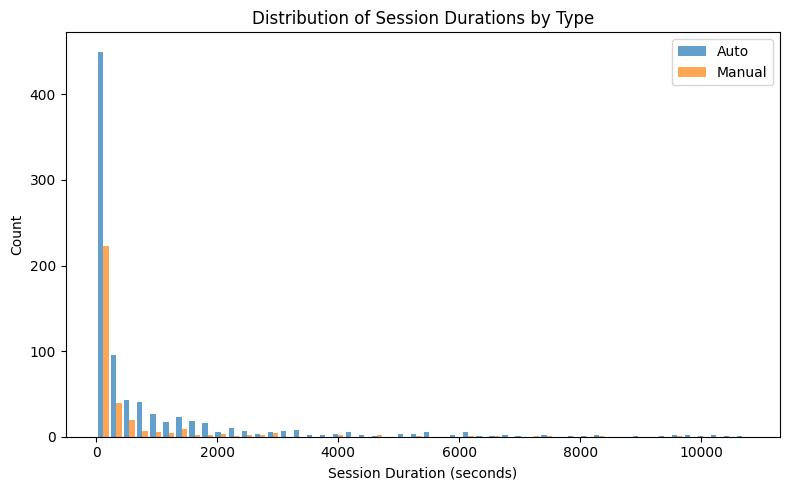

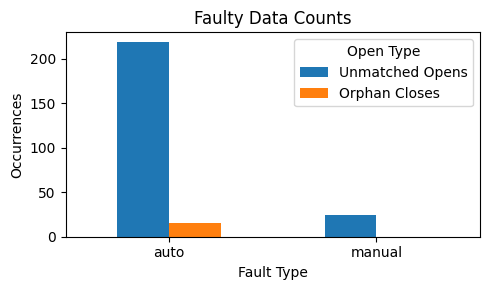

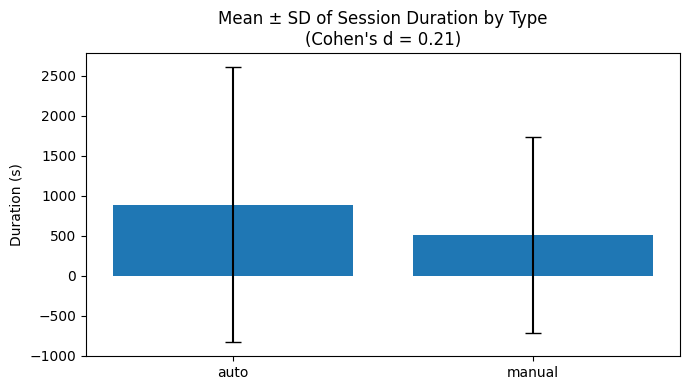

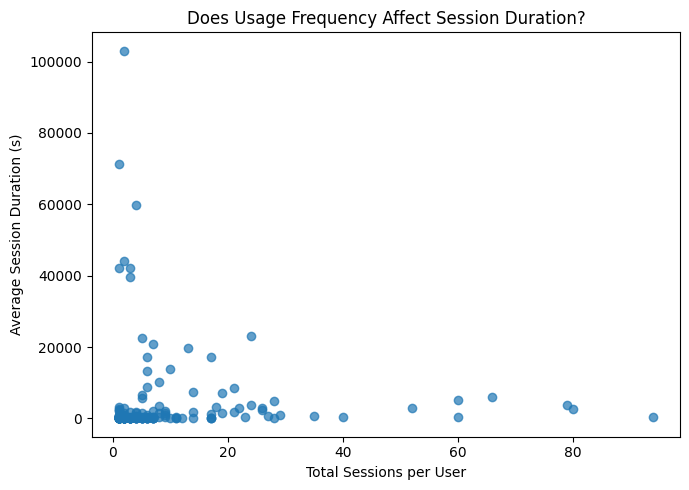

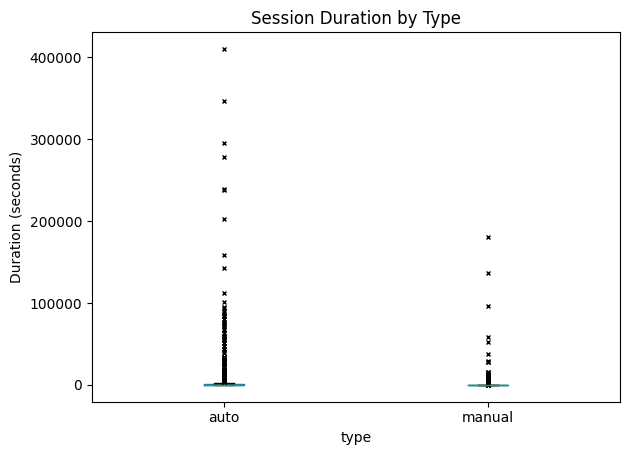

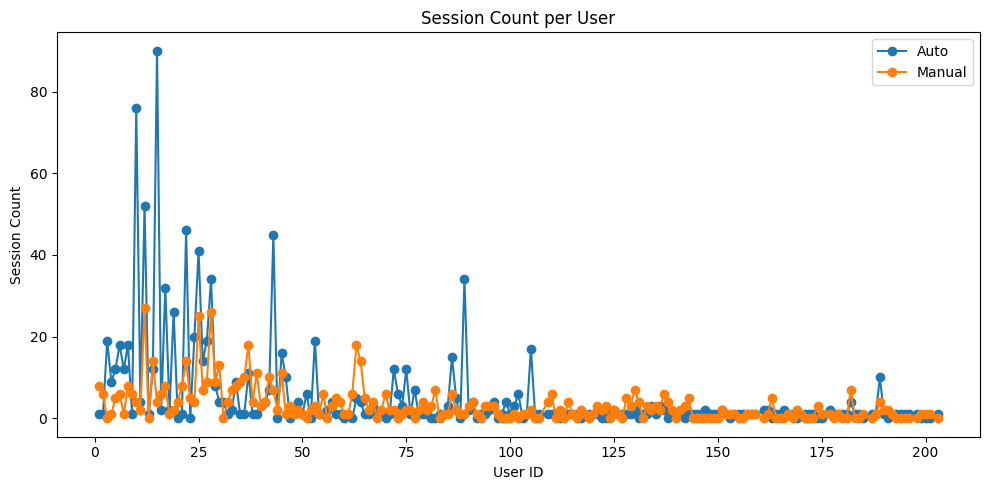

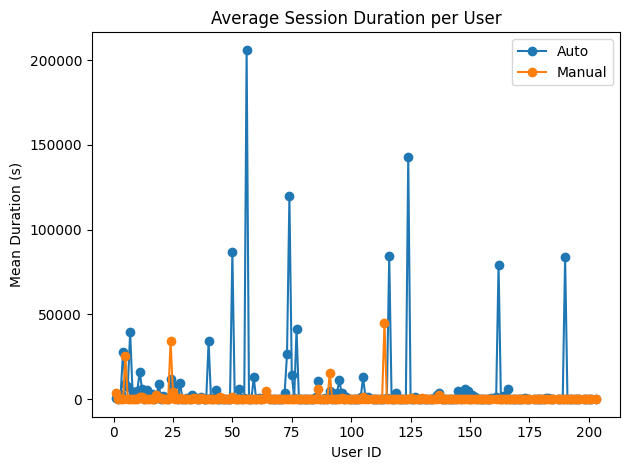

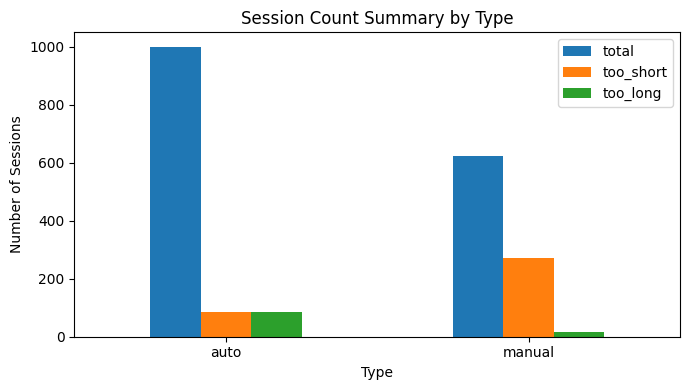

In [6]:
# Use the plotting functions from plots.py
plot_session_duration_distribution(basic_events)
plot_faulty_data(processor, labels=["Unmatched Opens", "Orphan Closes"])
plot_mean_sd_duration(mean_basic, std_dev_basic, cohens_d)
plot_sessions_vs_avg_duration(user_stats_pivot)
plot_session_duration_boxplot(time_spent)
plot_session_count_per_user(user_stats_pivot)
plot_avg_session_duration_per_user(user_stats_pivot)
plot_session_count_summary(summary)


## 6) Interpretation of results

Overall dataset had 3503 events recorded, of which 3244 successfully formed open-close pairs.
Rest, 259 (7.4%), are invalid, of which 243 are orphaned opens, and 16 excessive closes.
General duration mean is 6323s for auto events, and 1470s for manual ones.
After excluding "anomalies" (8 < t < 11000), 456 sessions in total (28.1%), mean became
889s and 505s for auto and manual respectively. Standard deviation was 1724s and 1225s.
Deviation for all sessions in general was not noted, as it was too big (due to anomalies).
p-value obtained through Welch’s t-test and Mann–Whitney U test is close to zero, which
means that there is real difference between groups and analysis is statistically significant.
Also, Cohen's d 0.21 indicates that effect size is somewhat small, but still significant.

Starting with the plots:
1) Distribution of session durations by type. This plot shows the analysis of filtered events, and shows that
most events are relatively short (10s-1000s) and mostly of auto type. Sessions that last 4000s-10000s are
few in number, and almost evenly distributed.
2) Faulty events. As we can see, most invalid open events are automatically created, only 6% are manual.
Amount of invalid closes is insignificant, their origin is hard to track.
3) Mean and SD. This plot operates on filtered data. The upper limit of blue boxes show the mean,
and long black bars show the range of standard deviation. Also, exact Cohen's d is displayed.
4) Plot number 4 shows correlation between session's amount and duration. As we can see, most
sessions are grouped under 4000s and 30 sessions. But there may be seen some extreme cases, such as
+-100 sessions per one user and over 100000s mean duration per one user. In general, it means that most users
tend to open tool window numerous times for a short period.
5) Distribution of session durations by type, boxplot. This plot is more convenient to research
through the standard pyplot window, as most of its data is concentrated in very small lower part.
Although we cannot clearly see the mean and quartiles, we can conclude that most events are concentrated around
1000s duration, but also there is a lot of outliers (data with big deviations), mostly of auto type.
Manual boxplot is generally "lower", as it shows lower durations and lower deviation.
6) This plot allows to generally assess, how much sessions each user had. Most users have had fairly even
amount of manual sessions, but some had a very big amount of auto ones, potentially impacting general analysis.
7) Mean duration of sessions by users. Once again, manual have low deviation (convenient to see enhanced in
pyplot interface), while auto sessions are unstable and in general 2-3 times longer.
8) This plot shows total amount of sessions compared to "anomalous" ones. Auto has moderate amount of long and
short events (8.4% and 8.4%), while all the rest was used during calculations. Manual almost doesn't have
too long sessions (2.6%), but there is a lot of short ones, supposedly opened "accidentally" (43.7%).
This fact significantly changed calculations after filtering those out.

Summarizing all of the results: auto is more commonly used than manual (1000 vs 622), especially after
filtering anomalies out (832 vs 344). But also auto provokes much more issues - multiple opens in a row,
opens without closes, very long sessions, etc., which makes it harder to analyze. Manual sessions are stable,
but, presumably, are often accidental (a lot of them last a few seconds). Users tend to open this window often,
but for a short amount of time, except some cases, when it is "open by default".


